In [1]:
from datasets import load_dataset

# Load labelled training reviews only; the official test split stays sealed
ds = load_dataset("stanfordnlp/imdb", data_files={"train": "plain_text/train-*"}, split="train")

C:\Users\20260009\OneDrive - TU Eindhoven\Vašek\EngD\Courses\Deep Learning\assignment\sentiment-ml-vs-dl\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ds

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

### Step 1: Preprocessing & Exploratory Data Analysis (EDA)
We will now clean the dataset, analyze length distributions, identify potential label leakage (explicit ratings), and create our stratified splits.

We use only the official training reviews during development. Labels are binary (0 = negative, 1 = positive); there is no neutral class. The unsupervised split is not used.

In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

# Keep the original row number to identify reviews later
train_df = pd.DataFrame(ds)
train_df['example_id'] = [f'train_{i:05d}' for i in range(len(train_df))]

print(f"Original train size: {len(train_df)}")

Original train size: 25000


In [4]:
train_df.head()

,text,label,example_id
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001
2,If only to avoid making this type of film in t...,0,train_00002
3,This film was probably inspired by Godard's Ma...,0,train_00003
4,"Oh, brother...after hearing about this ridicul...",0,train_00004


In [5]:
def clean_html(text):
    # Strip HTML tags like <br />
    return re.sub(r'<[^>]*>', ' ', text)

# 1. HTML Cleaning
train_df['cleaned_text'] = train_df['text'].apply(clean_html)

In [6]:
train_df.head()

,text,label,example_id,cleaned_text
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001,"""I Am Curious: Yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,0,train_00002,If only to avoid making this type of film in t...
3,This film was probably inspired by Godard's Ma...,0,train_00003,This film was probably inspired by Godard's Ma...
4,"Oh, brother...after hearing about this ridicul...",0,train_00004,"Oh, brother...after hearing about this ridicul..."


In [7]:
# 2. Normalize and Deduplicate
# Match exact duplicates after lowercasing and collapsing whitespace
# This does not detect paraphrases or other semantic near-duplicates
train_df['norm_text_for_dedup'] = (
    train_df['cleaned_text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
)

before_dedup = len(train_df)
train_df = train_df.drop_duplicates(subset=['norm_text_for_dedup']).copy()
after_dedup = len(train_df)

print(f"Removed {before_dedup - after_dedup} duplicate reviews from the training set.")
print(f"New training set size: {after_dedup}")

Removed 98 duplicate reviews from the training set.
New training set size: 24902


In [8]:
# 3. Find Explicit Ratings
rating_pattern = r'\b\d{1,2}(?:\.\d+)?\s*(?:/|out\s+of)\s*10\b'

def find_explicit_ratings(text):
    return re.search(rating_pattern, text, re.IGNORECASE) is not None

train_df['has_explicit_rating'] = train_df['cleaned_text'].apply(find_explicit_ratings)
leakage_rate = train_df['has_explicit_rating'].mean() * 100

print(f"Reviews containing explicit ratings: {leakage_rate:.2f}%")
train_df.loc[train_df['has_explicit_rating'], ['text', 'label']].head(3)

Reviews containing explicit ratings: 8.70%


,text,label
3,This film was probably inspired by Godard's Ma...,0
19,Pros: Nothing<br /><br />Cons: Everything<br /...,0
21,1st watched 8/3/2003 - 2 out of 10(Dir-Brad Sy...,0


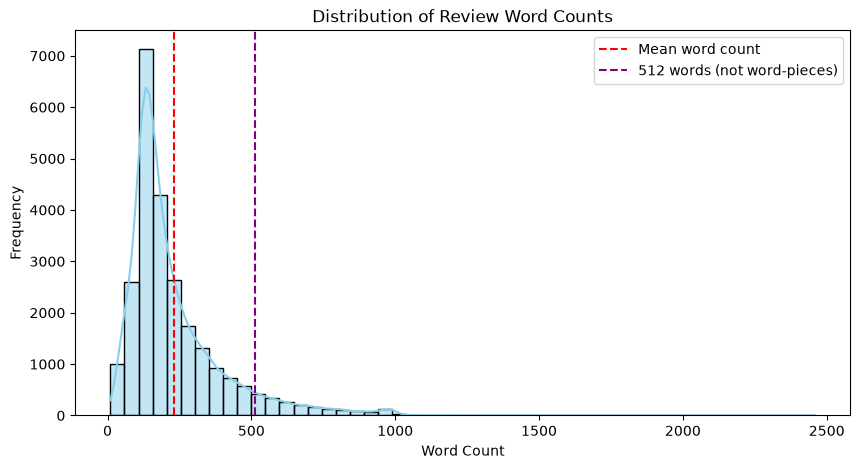

In [9]:
# 4. Length Analysis (Word Count distribution)
train_df['word_count'] = train_df['cleaned_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
sns.histplot(train_df['word_count'], bins=50, kde=True, color='skyblue')
plt.axvline(train_df['word_count'].mean(), color='red', linestyle='--', label='Mean word count')
plt.axvline(512, color='purple', linestyle='--', label='512 words (not word-pieces)')
plt.title('Distribution of Review Word Counts')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [10]:
print(f"Mean word count: {train_df['word_count'].mean():.1f}")
print(f"Median word count: {train_df['word_count'].median():.1f}")
print(f"Percentage of reviews exceeding 512 words: {(train_df['word_count'] > 512).mean() * 100:.2f}%")
print("Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.")

Mean word count: 231.7
Median word count: 173.0
Percentage of reviews exceeding 512 words: 7.45%
Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.


We will keep 5,000 reviews for development, with the same class balance as the training set. Using seed 42 gives us the same split each time.

In [11]:
# 5. Create a Stratified Train/Dev Split
from sklearn.model_selection import train_test_split

dev_df, train_split_df = train_test_split(
    train_df,
    train_size=5000,
    stratify=train_df['label'],
    random_state=SEED
)
train_split_df = train_split_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)

In [12]:
print(f"Train reviews: {len(train_split_df)}")
print(f"Dev reviews: {len(dev_df)}")
dev_df['label'].value_counts()

Train reviews: 19902
Dev reviews: 5000


label
1    2504
0    2496
Name: count, dtype: int64

### Step 2: TF-IDF Features
We will now turn the reviews into numerical features. We use single words and pairs of words, keeping stopwords so phrases like "not good" are retained. The vocabulary is learned from training reviews only.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

In [14]:
X_train = vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev = vectorizer.transform(dev_df['cleaned_text'])

y_train = train_split_df['label']
y_dev = dev_df['label']

print(f"Training feature matrix: {X_train.shape}")
print(f"Dev feature matrix: {X_dev.shape}")

Training feature matrix: (19902, 364489)
Dev feature matrix: (5000, 364489)


### Step 3: Baseline Models
Let's start with Logistic Regression and try three values of C. We choose the one with the highest dev accuracy and also report macro-F1. A small helper keeps the scoring the same for each model.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score

predictions = {}
scores = []

In [16]:
def evaluate_model(model, X, name):
    pred = model.predict(X)
    predictions[name] = dev_df[['example_id', 'label']].assign(
        model=name, pred=pred, prob=model.predict_proba(X)[:, 1]
    )
    scores.append({
        'model': name,
        'accuracy': accuracy_score(y_dev, pred),
        'macro_f1': f1_score(y_dev, pred, average='macro')
    })

In [17]:
# 1. Compare Three Values of C
lr_models = {}
for C in [0.1, 1, 10]:
    name = f'lr_C_{C:g}'
    model = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    model.fit(X_train, y_train)
    lr_models[name] = model
    evaluate_model(model, X_dev, name)

In [18]:
# A tie keeps the smaller C, since we tried values in ascending order
lr_results = pd.DataFrame(scores).sort_values('accuracy', ascending=False, kind='stable')
best_lr_name = lr_results.iloc[0]['model']
best_lr = lr_models[best_lr_name]
best_C = best_lr.C

print(f"Selected C: {best_C}")
lr_results

Selected C: 10


,model,accuracy,macro_f1
2,lr_C_10,0.9012,0.901198
1,lr_C_1,0.8890,0.888980
0,lr_C_0.1,0.8592,0.859113


Naive Bayes gives us a second, quick baseline. We can reuse the same TF-IDF features.

In [19]:
# 2. Train Naive Bayes
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)

evaluate_model(nb_model, X_dev, 'naive_bayes')
pd.DataFrame(scores)

,model,accuracy,macro_f1
0,lr_C_0.1,0.8592,0.859113
1,lr_C_1,0.8890,0.888980
2,lr_C_10,0.9012,0.901198
3,naive_bayes,0.8828,0.882774


### Step 4: Does Preprocessing Make a Difference?
We will now change one thing at a time, keeping the same split and selected C. First, does removing ratings such as "8/10" affect the result?

In [20]:
# 1. Remove Explicit Ratings from Both Sets
def remove_explicit_ratings(text):
    return re.sub(rating_pattern, ' ', text, flags=re.IGNORECASE)

train_no_ratings = train_split_df['cleaned_text'].apply(remove_explicit_ratings)
dev_no_ratings = dev_df['cleaned_text'].apply(remove_explicit_ratings)

In [21]:
# Fit a fresh vocabulary after removing the ratings
rating_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_ratings = rating_vectorizer.fit_transform(train_no_ratings)
X_dev_ratings = rating_vectorizer.transform(dev_no_ratings)

In [22]:
rating_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
rating_model.fit(X_train_ratings, y_train)

evaluate_model(rating_model, X_dev_ratings, 'lr_no_ratings')
pd.DataFrame(scores).tail(1)

,model,accuracy,macro_f1
4,lr_no_ratings,0.9012,0.9012


Next, let's remove English stopwords. This also removes words like "not", which could change the meaning of a review.

In [23]:
# 2. Try Stopword Removal on the Original Cleaned Text
stopword_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words='english'
)
X_train_stopwords = stopword_vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev_stopwords = stopword_vectorizer.transform(dev_df['cleaned_text'])

In [24]:
stopword_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
stopword_model.fit(X_train_stopwords, y_train)

evaluate_model(stopword_model, X_dev_stopwords, 'lr_stopwords')

In [25]:
# Compare all runs
results_df = pd.DataFrame(scores)
results_df

,model,accuracy,macro_f1
0,lr_C_0.1,0.8592,0.859113
1,lr_C_1,0.8890,0.888980
2,lr_C_10,0.9012,0.901198
3,naive_bayes,0.8828,0.882774
4,lr_no_ratings,0.9012,0.901200
5,lr_stopwords,0.8936,0.893589


In the first run, C = 10 gave 90.12% dev accuracy. Removing numeric ratings gave the same accuracy, while removing stopwords reduced it to 89.36%. We will keep stopwords for now. The rating check only covers the expressions matched by our regex.

### Step 5: A Closer Look at the Predictions
Overall accuracy does not show which class is harder. Let's compare precision, recall and the confusion matrices for our two baselines.

In [26]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

lr_predictions = predictions[best_lr_name]
nb_predictions = predictions['naive_bayes']

print("Logistic Regression")
print(classification_report(y_dev, lr_predictions['pred'], target_names=['negative', 'positive']))

Logistic Regression
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      2496
    positive       0.90      0.90      0.90      2504

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



In [27]:
print("Naive Bayes")
print(classification_report(y_dev, nb_predictions['pred'], target_names=['negative', 'positive']))

Naive Bayes
              precision    recall  f1-score   support

    negative       0.87      0.90      0.88      2496
    positive       0.90      0.87      0.88      2504

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



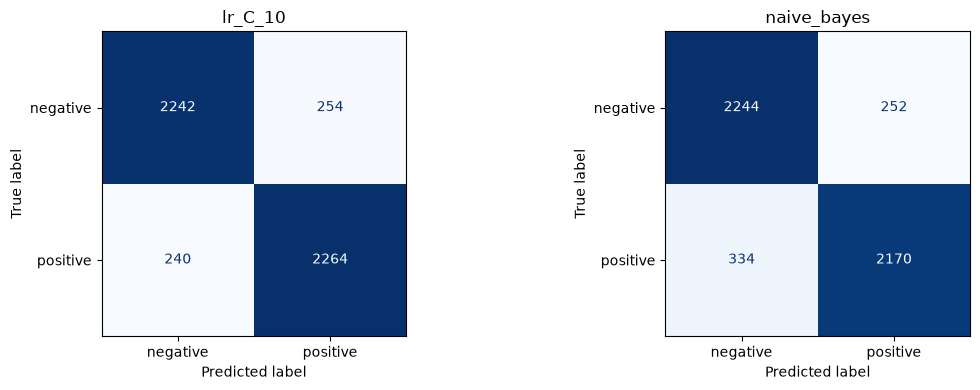

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, [best_lr_name, 'naive_bayes']):
    ConfusionMatrixDisplay.from_predictions(
        y_dev, predictions[name]['pred'], ax=ax,
        display_labels=['negative', 'positive'], cmap='Blues', colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

Are more confident predictions more often correct? Here, `prob` is the probability of a positive review, so confidence in the predicted class is the larger of `prob` and `1 - prob`.

In [29]:
confidence = pd.concat([lr_predictions, nb_predictions], ignore_index=True)
confidence['correct'] = confidence['pred'] == confidence['label']
confidence['confidence'] = np.maximum(confidence['prob'], 1 - confidence['prob'])
confidence['bucket'] = pd.cut(
    confidence['confidence'], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True
)

In [30]:
confidence_table = confidence.groupby(['model', 'bucket'], observed=False).agg(
    count=('correct', 'size'),
    accuracy=('correct', 'mean'),
    mean_confidence=('confidence', 'mean')
).reset_index()
confidence_table

,model,bucket,count,accuracy,mean_confidence
0,lr_C_10,"(0.499, 0.6]",397,0.564232,0.550505
1,lr_C_10,"(0.6, 0.7]",427,0.690867,0.651039
2,lr_C_10,"(0.7, 0.8]",552,0.817029,0.753329
3,lr_C_10,"(0.8, 0.9]",899,0.936596,0.854577
4,lr_C_10,"(0.9, 1.0]",2725,0.988624,0.964329
5,naive_bayes,"(0.499, 0.6]",789,0.623574,0.551871
6,naive_bayes,"(0.6, 0.7]",915,0.802186,0.654205
7,naive_bayes,"(0.7, 0.8]",1125,0.931556,0.752344
8,naive_bayes,"(0.8, 0.9]",1295,0.976834,0.850612
9,naive_bayes,"(0.9, 1.0]",876,0.998858,0.939849


Finally, let's read some mistakes. We sample 50 Logistic Regression errors for both reviewers to label independently. Possible causes include negation, contrast, sarcasm, plot description, mixed opinions, comparisons and long reviews.

In [31]:
errors = lr_predictions.loc[lr_predictions['pred'] != lr_predictions['label']]
error_sample = errors.sample(n=min(50, len(errors)), random_state=SEED)
error_sample = error_sample.merge(
    dev_df[['example_id', 'cleaned_text', 'word_count', 'has_explicit_rating']], on='example_id'
)

print(f"Logistic Regression errors: {len(errors)}")
error_sample[['label', 'pred', 'cleaned_text']].head()

Logistic Regression errors: 494


,label,pred,cleaned_text
0,1,0,"I'm a fan of C&C, going back to their records,..."
1,0,1,The 1930' were a golden age of Los Angeles wit...
2,1,0,Ask yourself where she got the gun? Remember w...
3,1,0,I have just finished watching this film and I ...
4,1,0,"Guns blasting, buildings exploding, cars crash..."


In [32]:
# Read one full review rather than just the shortened table preview
example = error_sample.iloc[0]
print(f"True label: {example['label']} | Predicted label: {example['pred']}")
print(example['cleaned_text'])

True label: 1 | Predicted label: 0
I'm a fan of C&C, going back to their records, and liked this movie, but at one point in the mid-1980's on cable television in San Jose California, it was aired with an alternate plot line that destroyed the entire point of the movie. All references to marijuana were replaced with "diamonds". The bag that "Red" drops to Chong has diamonds in it instead of marijuana, but the conversation still remains the same ("...it's worth ~$3000/lb"). There is also a subplot in which clips of aliens on a ship were added observing C&C, and talking to each other about getting the diamonds. At the end, instead of "space coke", it's something else. I'm not sure who created this version, but it was horrible, and obvious that they were attempting to make it family/child friendly. It would have been better if that network had not aired it at all.


### Step 6: What Comes Next?
Next we will compare these baselines with DistilBERT using the same split. We will try different truncation lengths and training sizes (1,000, 5,000 and all 19,902 training reviews), then inspect errors from both models.

These are dev results. Once all settings are fixed, we will evaluate on the official test set and calculate confidence intervals and McNemar's test.